# Assignment: Real-Time Intrusion Detection with Scapy + PyTorch

## Task 1: Dataset Exploration and Feature Understanding


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

def find_project_root(start: Path | None = None) -> Path:
    start = start or Path.cwd()
    for candidate in [start, *start.parents]:
        if (candidate / "datasets").is_dir():
            return candidate
    return start

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "datasets"

files = sorted(DATA_DIR.glob("*.csv"))
# Exclude generated logs
files = [p for p in files if p.name != "network_log.csv"]

print(f"Dataset dir: {DATA_DIR}")
print(f"Found {len(files)} files.")

if files:
    # LOAD ALL DATA
    print("Loading ALL files... this may take memory.")
    li = []
    for path in files:
        df_temp = pd.read_csv(path, index_col=None, header=0)
        li.append(df_temp)
    
    df = pd.concat(li, axis=0, ignore_index=True)
    
    # Strip whitespace from headers
    df.columns = df.columns.str.strip()
    
    print(f"Full Dataset Shape: {df.shape}")
else:
    print(f"No data found in: {DATA_DIR}")

Dataset dir: d:\coding\python\MachileLearning\ML-assignement\datasets
Found 8 files.
Loading ALL files... this may take memory.
Full Dataset Shape: (2830743, 79)


### 1. List of All Features
Loading the dataset and listing all available feature names.


In [3]:
if 'df' in locals():
    print(f"Total Features: {len(df.columns)}")
    display(pd.DataFrame(df.columns, columns=['Feature Name']))


Total Features: 79


,Feature Name
0,Destination Port
1,Flow Duration
2,Total Fwd Packets
3,Total Backward Packets
4,Total Length of Fwd Packets
5,Total Length of Bwd Packets
6,Fwd Packet Length Max
7,Fwd Packet Length Min
8,Fwd Packet Length Mean
9,Fwd Packet Length Std


### 2. Feature Analysis (Name, Type, Description, Relevance)
The following table provides the Name, Data Type, Description, and Justification (Relevance) for **each** feature.


In [4]:
# Comprehensive Feature Definitions
features_metadata = {
    'Destination Port': {'type': 'int', 'desc': 'Destination port number', 'level': 'Packet', 'relevance': 'Identifies compromised service.'},
    'Flow Duration': {'type': 'int', 'desc': 'Duration of the flow in microseconds', 'level': 'Flow', 'relevance': 'DDoS/Bruteforce result in short/long durations.'},
    'Total Fwd Packets': {'type': 'int', 'desc': 'Total packets in forward direction', 'level': 'Flow', 'relevance': 'Volume metric.'},
    'Total Backward Packets': {'type': 'int', 'desc': 'Total packets in backward direction', 'level': 'Flow', 'relevance': 'Volume metric.'},
    'Total Length of Fwd Packets': {'type': 'int', 'desc': 'Total size of packet payload in forward direction', 'level': 'Flow', 'relevance': 'Data exfiltration volume.'},
    'Total Length of Bwd Packets': {'type': 'int', 'desc': 'Total size of packet payload in backward direction', 'level': 'Flow', 'relevance': 'Download volume.'},
    'Fwd Packet Length Max': {'type': 'int', 'desc': 'Maximum size of packet in forward direction', 'level': 'Flow', 'relevance': 'MTU anomalies.'},
    'Fwd Packet Length Min': {'type': 'int', 'desc': 'Minimum size of packet in forward direction', 'level': 'Flow', 'relevance': 'Control packets.'},
    'Fwd Packet Length Mean': {'type': 'float', 'desc': 'Average size of packet in forward direction', 'level': 'Flow', 'relevance': 'Profile of application protocol.'},
    'Fwd Packet Length Std': {'type': 'float', 'desc': 'Standard deviation size of packet in forward direction', 'level': 'Flow', 'relevance': 'Variability of payload.'},
    'Bwd Packet Length Max': {'type': 'int', 'desc': 'Maximum size of packet in backward direction', 'level': 'Flow', 'relevance': ''},
    'Bwd Packet Length Min': {'type': 'int', 'desc': 'Minimum size of packet in backward direction', 'level': 'Flow', 'relevance': ''},
    'Bwd Packet Length Mean': {'type': 'float', 'desc': 'Mean size of packet in backward direction', 'level': 'Flow', 'relevance': ''},
    'Bwd Packet Length Std': {'type': 'float', 'desc': 'Standard deviation size of packet in backward direction', 'level': 'Flow', 'relevance': ''},
    'Flow Bytes/s': {'type': 'float', 'desc': 'Flow throughput in bytes per second', 'level': 'Flow', 'relevance': 'Bandwidth usage.'},
    'Flow Packets/s': {'type': 'float', 'desc': 'Flow throughput in packets per second', 'level': 'Flow', 'relevance': 'High PPS indicates DDoS.'},
    'Flow IAT Mean': {'type': 'float', 'desc': 'Mean time between two packets in the flow', 'level': 'Flow', 'relevance': 'Automated traffic has regular IAT.'},
    'Flow IAT Std': {'type': 'float', 'desc': 'Standard deviation of time between two packets', 'level': 'Flow', 'relevance': 'Jitter.'},
    'Flow IAT Max': {'type': 'int', 'desc': 'Maximum time between two packets', 'level': 'Flow', 'relevance': 'Idle periods.'},
    'Flow IAT Min': {'type': 'int', 'desc': 'Minimum time between two packets', 'level': 'Flow', 'relevance': 'Bursts.'},
    'Fwd IAT Total': {'type': 'int', 'desc': 'Total time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd IAT Mean': {'type': 'float', 'desc': 'Mean time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd IAT Std': {'type': 'float', 'desc': 'Standard deviation of time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd IAT Max': {'type': 'int', 'desc': 'Maximum time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd IAT Min': {'type': 'int', 'desc': 'Minimum time between two forward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Total': {'type': 'int', 'desc': 'Total time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Mean': {'type': 'float', 'desc': 'Mean time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Std': {'type': 'float', 'desc': 'Standard deviation of time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Max': {'type': 'int', 'desc': 'Maximum time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Bwd IAT Min': {'type': 'int', 'desc': 'Minimum time between two backward packets', 'level': 'Flow', 'relevance': ''},
    'Fwd PSH Flags': {'type': 'int', 'desc': 'Number of times the PSH flag was set in forward direction', 'level': 'Flow/Packet', 'relevance': 'Data push urgency.'},
    'Bwd PSH Flags': {'type': 'int', 'desc': 'Number of times the PSH flag was set in backward direction', 'level': 'Flow/Packet', 'relevance': ''},
    'Fwd URG Flags': {'type': 'int', 'desc': 'Number of times the URG flag was set in forward direction', 'level': 'Flow/Packet', 'relevance': ''},
    'Bwd URG Flags': {'type': 'int', 'desc': 'Number of times the URG flag was set in backward direction', 'level': 'Flow/Packet', 'relevance': ''},
    'Fwd Header Length': {'type': 'int', 'desc': 'Total bytes used for headers in forward direction', 'level': 'Flow', 'relevance': 'Tunneling overhead.'},
    'Bwd Header Length': {'type': 'int', 'desc': 'Total bytes used for headers in backward direction', 'level': 'Flow', 'relevance': ''},
    'Fwd Packets/s': {'type': 'float', 'desc': 'Number of forward packets per second', 'level': 'Flow', 'relevance': ''},
    'Bwd Packets/s': {'type': 'float', 'desc': 'Number of backward packets per second', 'level': 'Flow', 'relevance': ''},
    'Min Packet Length': {'type': 'int', 'desc': 'Minimum length of a packet', 'level': 'Flow', 'relevance': ''},
    'Max Packet Length': {'type': 'int', 'desc': 'Maximum length of a packet', 'level': 'Flow', 'relevance': ''},
    'Packet Length Mean': {'type': 'float', 'desc': 'Mean length of a packet', 'level': 'Flow', 'relevance': ''},
    'Packet Length Std': {'type': 'float', 'desc': 'Standard deviation of length of a packet', 'level': 'Flow', 'relevance': ''},
    'Packet Length Variance': {'type': 'float', 'desc': 'Variance of length of a packet', 'level': 'Flow', 'relevance': ''},
    'FIN Flag Count': {'type': 'int', 'desc': 'Number of packets with FIN', 'level': 'Flow', 'relevance': 'Connection termination.'},
    'SYN Flag Count': {'type': 'int', 'desc': 'Number of packets with SYN', 'level': 'Flow', 'relevance': 'Connection establishment.'},
    'RST Flag Count': {'type': 'int', 'desc': 'Number of packets with RST', 'level': 'Flow', 'relevance': 'Connection reset.'},
    'PSH Flag Count': {'type': 'int', 'desc': 'Number of packets with PSH', 'level': 'Flow', 'relevance': ''},
    'ACK Flag Count': {'type': 'int', 'desc': 'Number of packets with ACK', 'level': 'Flow', 'relevance': ''},
    'URG Flag Count': {'type': 'int', 'desc': 'Number of packets with URG', 'level': 'Flow', 'relevance': ''},
    'CWE Flag Count': {'type': 'int', 'desc': 'Number of packets with CWE', 'level': 'Flow', 'relevance': 'Congestion Window ECN.'},
    'ECE Flag Count': {'type': 'int', 'desc': 'Number of packets with ECE', 'level': 'Flow', 'relevance': 'ECN-Echo.'},
    'Down/Up Ratio': {'type': 'float', 'desc': 'Download and upload ratio', 'level': 'Flow', 'relevance': 'Traffic directionality.'},
    'Average Packet Size': {'type': 'float', 'desc': 'Average size of packet', 'level': 'Flow', 'relevance': ''},
    'Avg Fwd Segment Size': {'type': 'float', 'desc': 'Average size observed in the forward direction', 'level': 'Flow', 'relevance': ''},
    'Avg Bwd Segment Size': {'type': 'float', 'desc': 'Average size observed in the backward direction', 'level': 'Flow', 'relevance': ''},
    'Fwd Header Length.1': {'type': 'int', 'desc': 'Duplicate column (Header Length)', 'level': 'Flow', 'relevance': ''},
    'Fwd Avg Bytes/Bulk': {'type': 'int', 'desc': 'Average bytes/bulk in forward', 'level': 'Flow', 'relevance': ''},
    'Fwd Avg Packets/Bulk': {'type': 'int', 'desc': 'Average packets/bulk in forward', 'level': 'Flow', 'relevance': ''},
    'Fwd Avg Bulk Rate': {'type': 'int', 'desc': 'Average bulk rate in forward', 'level': 'Flow', 'relevance': ''},
    'Bwd Avg Bytes/Bulk': {'type': 'int', 'desc': 'Average bytes/bulk in backward', 'level': 'Flow', 'relevance': ''},
    'Bwd Avg Packets/Bulk': {'type': 'int', 'desc': 'Average packets/bulk in backward', 'level': 'Flow', 'relevance': ''},
    'Bwd Avg Bulk Rate': {'type': 'int', 'desc': 'Average bulk rate in backward', 'level': 'Flow', 'relevance': ''},
    'Subflow Fwd Packets': {'type': 'int', 'desc': 'The average number of packets in a subflow in the forward direction', 'level': 'Flow', 'relevance': ''},
    'Subflow Fwd Bytes': {'type': 'int', 'desc': 'The average number of bytes in a subflow in the forward direction', 'level': 'Flow', 'relevance': ''},
    'Subflow Bwd Packets': {'type': 'int', 'desc': 'The average number of packets in a subflow in the backward direction', 'level': 'Flow', 'relevance': ''},
    'Subflow Bwd Bytes': {'type': 'int', 'desc': 'The average number of bytes in a subflow in the backward direction', 'level': 'Flow', 'relevance': ''},
    'Init_Win_bytes_forward': {'type': 'int', 'desc': 'Total number of bytes sent in initial window in the forward direction', 'level': 'Flow', 'relevance': 'TCP Window scaling detected.'},
    'Init_Win_bytes_backward': {'type': 'int', 'desc': 'Total number of bytes sent in initial window in the backward direction', 'level': 'Flow', 'relevance': ''},
    'act_data_pkt_fwd': {'type': 'int', 'desc': 'Count of packets with at least 1 byte of TCP data payload in forward direction', 'level': 'Flow', 'relevance': 'Actual data transfer vs control.'},
    'min_seg_size_forward': {'type': 'int', 'desc': 'Minimum segment size observed in the forward direction', 'level': 'Flow', 'relevance': ''},
    'Active Mean': {'type': 'float', 'desc': 'Mean time a flow was active before becoming idle', 'level': 'Flow', 'relevance': 'Active/Sleep cycles.'},
    'Active Std': {'type': 'float', 'desc': 'Standard deviation time a flow was active', 'level': 'Flow', 'relevance': ''},
    'Active Max': {'type': 'int', 'desc': 'Maximum time a flow was active', 'level': 'Flow', 'relevance': ''},
    'Active Min': {'type': 'int', 'desc': 'Minimum time a flow was active', 'level': 'Flow', 'relevance': ''},
    'Idle Mean': {'type': 'float', 'desc': 'Mean time a flow was idle', 'level': 'Flow', 'relevance': 'Beaconing behavior.'},
    'Idle Std': {'type': 'float', 'desc': 'Standard deviation time a flow was idle', 'level': 'Flow', 'relevance': ''},
    'Idle Max': {'type': 'int', 'desc': 'Maximum time a flow was idle', 'level': 'Flow', 'relevance': ''},
    'Idle Min': {'type': 'int', 'desc': 'Minimum time a flow was idle', 'level': 'Flow', 'relevance': ''},
    'Label': {'type': 'str', 'desc': 'The class label (Benign or specific Attack)', 'level': 'Meta', 'relevance': 'Target variable.'}
}

def get_feature_info(col_name):
    # Try exact match or match derived names
    meta = features_metadata.get(col_name)
    if not meta:
        return {'Name': col_name, 'Type': 'Unknown', 'Description': 'Feature not manually mapped', 'Level': 'Unknown', 'Relevance': 'Unknown'}
    return {
        'Name': col_name,
        'Type': meta['type'],
        'Description': meta['desc'],
        'Level': meta['level'],
        'Relevance': meta['relevance']
    }

if 'df' in locals():
    feature_list_data = [get_feature_info(col) for col in df.columns] # type: ignore
    df_features = pd.DataFrame(feature_list_data)
    display(df_features)


,Name,Type,Description,Level,Relevance
0,Destination Port,int,Destination port number,Packet,Identifies compromised service.
1,Flow Duration,int,Duration of the flow in microseconds,Flow,DDoS/Bruteforce result in short/long durations.
2,Total Fwd Packets,int,Total packets in forward direction,Flow,Volume metric.
3,Total Backward Packets,int,Total packets in backward direction,Flow,Volume metric.
4,Total Length of Fwd Packets,int,Total size of packet payload in forward direction,Flow,Data exfiltration volume.
5,Total Length of Bwd Packets,int,Total size of packet payload in backward direction,Flow,Download volume.
6,Fwd Packet Length Max,int,Maximum size of packet in forward direction,Flow,MTU anomalies.
7,Fwd Packet Length Min,int,Minimum size of packet in forward direction,Flow,Control packets.
8,Fwd Packet Length Mean,float,Average size of packet in forward direction,Flow,Profile of application protocol.
9,Fwd Packet Length Std,float,Standard deviation size of packet in forward direction,Flow,Variability of payload.


### 3. Summary of Packet vs Flow Level Features

**Packet-Level Features** are those that can be derived from the headers or payload of a **single** packet, without any historical context or state.
*   **Examples**: `Destination Port` (TCP Header), `Protocol` (IP Header), `Packet Length` (IP Header), `Flags` (TCP Header) *of a specific packet*.
*   **Characteristics**: Extremely fast to extract (O(1)).

**Flow-Level (Derived/Aggregated) Features** are calculated by tracking statistics over a sequence of packets.
*   **Clarification on 'Packet Length Max'**: Even though `Fwd Packet Length Max` has "Packet" in the name, it is a **Flow** feature. Why? Because to know the "Max", you must observe *all* packets in the flow (or a window) to find the largest one. A single packet cannot know if it is the "Max" of the whole stream.
*   **Examples**: `Flow Duration`, `Total Fwd Packets`, `Fwd Packet Length Max/Mean/Std`.
*   **Characteristics**: Require state maintenance (hash tables) and memory.


## Task 2: Identify Scapy-Computable Features

We select a subset of features that are feasible to calculate in real-time using Scapy.

### Computability Table

| Feature | Linux Server? | Raspberry Pi? | Reason | Validation Snippet |
|---|---|---|---|---|
| **Src/Dst IP & Port** | Yes | Yes | Basic header parsing, negligible cost. | `pkt[IP].src`, `pkt[TCP].sport` |
| **Packet Length** | Yes | Yes | `len(pkt)`, immediate availability. | `len(packet)` |
| **TCP Flags** | Yes | Yes | Parsing TCP header is lightweight. | `pkt[TCP].flags` |
| **Flow Duration** | Yes | Yes (Low traffic) | Requires hash map lookup. On Pi, high RAM usage if many concurrent flows. | `now - flow_start_time[flow_id]` |
| **Packet Number/Count** | Yes | Yes (Low traffic) | Simple counter in hash map. | `flows[id]['count'] += 1` |
| **Inter-Arrival Time (IAT)** | Yes | Maybe | Requires storing timestamp of *last* packet. Calculation is cheap, but state management adds up. | `now - last_seen[flow_id]` |
| **Bytes/s** | Yes | Maybe | Derived from Count/Duration. Floating point div is cheap, but state is the bottleneck. | `total_bytes / duration` |

### Justification:
*   **Raspberry Pi Limitations**: Limited RAM and CPU. Keeping state for 100k+ concurrent flows (common in DDoS) will exhaust RAM or cause packet drops due to processing latency (Python/Scapy overhead). Feature extraction must be kept to O(1) or O(log n) with small n.
*   **Selected Subset for Task 3**:
    1.  **Basic 5-tuple**: Src IP, Dst IP, Src Port, Dst Port, Protocol.
    2.  **Packet Size**: `len(packet)`.
    3.  **TCP Flags**: (SYN, ACK, FIN, RST, PSH, URG).
    4.  **Flow Stats (Simplified)**: Packet Count, Byte Count (per flow).


## Task 3: Real-Time Scapy Extractor

This script will:
1.  Detect OS.
2.  Sniff traffic.
3.  Extract features.
4.  Log to CSV.


In [5]:
import platform
import os
import time
import csv
from collections import defaultdict
from datetime import datetime
from scapy.all import sniff
from scapy.layers.inet import IP, TCP, UDP

# 1. Detect OS
def get_system_info():
    sys_type = platform.system()
    node = platform.node()
    machine = platform.machine()
    is_pi = 'arm' in machine.lower() or 'aarch64' in machine.lower() or 'raspberry' in node.lower()
    return {
        "OS": sys_type,
        "Node": node,
        "Is_Pi": is_pi
    }

sys_info = get_system_info()
print(f"Running on: {sys_info['OS']} ({sys_info['Node']})")
print(f"Target Hardware: {'Raspberry Pi' if sys_info['Is_Pi'] else 'Likely Server/PC'}")

# 2. & 3. Scapy Extractor
class RealTimeExtractor:
    def __init__(self, filename="network_log.csv"):
        self.output_dir = "datasets"
        if not os.path.exists(self.output_dir):
            os.makedirs(self.output_dir)
            print(f"Dossier '{self.output_dir}' créé.")
        self.log_file = os.path.join(self.output_dir, filename)
        self.flow_table = defaultdict(lambda: {'start_time': 0, 'packet_count': 0, 'byte_count': 0})
        
        # Initialize CSV
        self.features = ['timestamp', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'proto', 
                         'flag', 'packet_len', 'flow_duration', 'flow_pkt_count']
        
        if os.path.exists(self.log_file):
            print(f"ATTENTION : Le fichier '{self.log_file}' existe déjà.")
            self.skip_writing = True
        else:
            print(f"Création du nouveau fichier : {self.log_file}")
            self.skip_writing = False
            with open(self.log_file, 'w', newline='') as f:
                writer = csv.DictWriter(f, fieldnames=self.features)
                writer.writeheader()
                
        with open(self.log_file, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=self.features)
            writer.writeheader()
            
    def process_packet(self, pkt):
        if self.skip_writing:
            return
        try:
            if IP not in pkt:
                return

            row = {}
            ip = pkt[IP]
            row['timestamp'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S.%f')
            row['src_ip'] = ip.src
            row['dst_ip'] = ip.dst
            row['proto'] = ip.proto
            row['packet_len'] = len(pkt)
            
            # Layer 4
            sport = 0
            dport = 0
            flags = 'None'
            
            if TCP in pkt:
                sport = pkt[TCP].sport
                dport = pkt[TCP].dport
                flags = str(pkt[TCP].flags)
            elif UDP in pkt:
                sport = pkt[UDP].sport
                dport = pkt[UDP].dport
                flags = 'UDP'
            
            row['src_port'] = sport
            row['dst_port'] = dport
            row['flag'] = flags
            
            # Flow Tracking (Simplified)
            flow_id = (ip.src, ip.dst, sport, dport, ip.proto)
            curr_time = time.time()
            
            if self.flow_table[flow_id]['packet_count'] == 0:
                self.flow_table[flow_id]['start_time'] = curr_time # type: ignore
            
            self.flow_table[flow_id]['packet_count'] += 1
            self.flow_table[flow_id]['byte_count'] += len(pkt)
            
            row['flow_duration'] = curr_time - self.flow_table[flow_id]['start_time']
            row['flow_pkt_count'] = self.flow_table[flow_id]['packet_count']
            
            # Log
            with open(self.log_file, 'a', newline='') as f:
                writer = csv.DictWriter(f, fieldnames=self.features)
                writer.writerow(row)
                
            # Verify/Print (Optional, print every 10th packet to reduce noise)
            if self.flow_table[flow_id]['packet_count'] % 10 == 1:
                print(f"Logged: {row['src_ip']} -> {row['dst_ip']} | Len: {row['packet_len']}")

        except Exception as e:
            # print(f"Error: {e}")
            pass

# Run Sniffer (Limited count for Notebook demonstration)
print("Starting Sniffer for 50 packets...")
extractor = RealTimeExtractor()
try:
    if extractor.skip_writing:
        print("The file already exists, the sniffer will not start.")
    else:
        print("Starting Sniffer...")
        sniff(prn=extractor.process_packet, count=50, timeout=10, store=0)
        print("Finished.")
except Exception as e:
    print(f"Error: {e}")


Running on: Windows (DESKTOP-H4RK4S0)
Target Hardware: Likely Server/PC
Starting Sniffer for 50 packets...
ATTENTION : Le fichier 'datasets\network_log.csv' existe déjà.
The file already exists, the sniffer will not start.


## Task 4 — Prepare Platform-Specific Datasets

On construit deux sous-datasets à partir de CIC-IDS2017 :

- **Linux (real-time)** : features calculables en temps réel sur un serveur (packet header + statistiques de flot raisonnables avec état en mémoire).
- **Raspberry Pi (real-time)** : sous-ensemble plus léger (header + compteurs simples) pour limiter CPU/RAM.

Préprocessing appliqué aux deux sous-datasets :
1. Remplacement des infinis par NaN puis suppression des lignes NaN.
2. Encodage du label.
3. Normalisation (StandardScaler) sur les features numériques.
4. Split Train/Val/Test (stratifié si possible).


In [6]:
# Define Columns for Pi Subset identified in Task 2
# (Keep the same variable name: columns_pi)
columns_pi = [
    "Destination Port",
    "Protocol",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Fwd Packet Length Mean",
    "Fwd Packet Length Min",
    "Fwd Packet Length Max",
    "Packet Length Mean",
    "FIN Flag Count",
    "SYN Flag Count",
    "RST Flag Count",
    "PSH Flag Count",
    "ACK Flag Count",
    "URG Flag Count",
    "Down/Up Ratio",
    "Label",
]

# Define Columns for Linux Subset (computable real-time on a server)
# (New list but does not rename existing variables; just adds a linux list)
columns_linux = [
    "Destination Port",
    "Protocol",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Fwd Packet Length Mean",
    "Bwd Packet Length Mean",
    "Packet Length Mean",
    "Packet Length Std",
    "SYN Flag Count",
    "ACK Flag Count",
    "RST Flag Count",
    "FIN Flag Count",
    "Down/Up Ratio",
    "Active Mean",
    "Idle Mean",
    "Label",
]

# 1. Use Data Already loaded FULL df in Step 1
if 'df' not in locals():
    print("DataFrame df not found. Please run the Load Data cell first.")
else:
    print(f"Using full dataset with shape: {df.shape}")

    # 2. Split (keep the same names dfpi, dflinux)
    cols_pi_present = [c for c in columns_pi if c in df.columns]
    cols_linux_present = [c for c in columns_linux if c in df.columns]

    dfpi = df[cols_pi_present].copy()
    dflinux = df[cols_linux_present].copy()

    print(f"Pi Dataset Shape: {dfpi.shape}")
    print(f"Linux Dataset Shape: {dflinux.shape}")

    # 3. Preprocessing Function (keep same function name and return variables)
    def preprocess_dataset(dataframe, nameDataset):
        print(f"--- Preprocessing {nameDataset} ---")

        # Handle Inf/NaN
        df_clean = dataframe.replace([np.inf, -np.inf], np.nan).dropna()
        print(f"Dropped {len(dataframe) - len(df_clean)} rows with NaN/Inf.")

        # Separate Label
        if "Label" in df_clean.columns:
            y = df_clean["Label"].astype(str)
            X = df_clean.drop(columns=["Label"])
        else:
            print("Warning: Label column not found.")
            return None, None, 0, None, None, None, None

        # Encode Label
        le = LabelEncoder()
        y_encoded = le.fit_transform(y)
        print("Labels encoded:", le.classes_)
        num_classes = len(le.classes_)

        # Scale Features
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        # Convert back to DataFrame for display
        X_final = pd.DataFrame(X_scaled, columns=X.columns)
        print(f"Final Feature Shape: {X_final.shape}")

        # Split train/val/test (70/15/15) to support Task 6 properly
        X_train, X_temp, y_train, y_temp = train_test_split(
            X_final.values, y_encoded, test_size=0.30, random_state=42, stratify=y_encoded
        )
        X_val, X_test, y_val, y_test = train_test_split(
            X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
        )

        # Determine device (keep the same prints)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        print("Using device:", device)

        return (pd.DataFrame(X_train, columns=X.columns), y_train, num_classes,
                pd.DataFrame(X_val, columns=X.columns), y_val,
                pd.DataFrame(X_test, columns=X.columns), y_test), scaler, le

    # Process Both We will process and store in variables for Task 5
    try:
        (Xpiprocessed, ypiprocessed, numclasses,
         Xpi_val, ypi_val,
         Xpi_test, ypi_test), scaler_pi, le_pi = preprocess_dataset(dfpi, "Raspberry Pi Dataset") # type: ignore

        (Xlinuxprocessed, ylinuxprocessed, numclasses_linux,
         Xlinux_val, ylinux_val,
         Xlinux_test, ylinux_test), scaler_linux, le_linux = preprocess_dataset(dflinux, "Linux Dataset") # type: ignore

        # Keep numclasses consistent (prefer Linux encoder, but don't rename variable)
        numclasses = max(numclasses, numclasses_linux)

    except MemoryError:
        print("Error: Memory limit reached during preprocessing of the full dataset.")


Using full dataset with shape: (2830743, 79)
Pi Dataset Shape: (2830743, 18)
Linux Dataset Shape: (2830743, 20)
--- Preprocessing Raspberry Pi Dataset ---
Dropped 0 rows with NaN/Inf.
Labels encoded: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack � Brute Force' 'Web Attack � Sql Injection'
 'Web Attack � XSS']
Final Feature Shape: (2830743, 17)
Using device: cuda
--- Preprocessing Linux Dataset ---
Dropped 2867 rows with NaN/Inf.
Labels encoded: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack � Brute Force' 'Web Attack � Sql Injection'
 'Web Attack � XSS']
Final Feature Shape: (2827876, 19)
Using device: cuda


## Task 5: Train and Optimize PyTorch Models

We will train 3 models (MLP, CNN, Transformer) on both datasets (`df_pi`, `df_linux`) with Hyperparameter Tuning.



=== Tuning Models for Pi_Dataset ===

--- Training MLP ---
Testing params: {'lr': 0.001, 'hidden_dim': 64}
Epoch 1/3: Train Loss: 0.1199, Val Loss: 0.0951, Val Acc: 0.9637
Epoch 2/3: Train Loss: 0.0781, Val Loss: 0.0678, Val Acc: 0.9745
Epoch 3/3: Train Loss: 0.0623, Val Loss: 0.0574, Val Acc: 0.9846
Testing params: {'lr': 0.0001, 'hidden_dim': 128}
Epoch 1/3: Train Loss: 0.1853, Val Loss: 0.1237, Val Acc: 0.9640
Epoch 2/3: Train Loss: 0.1091, Val Loss: 0.1031, Val Acc: 0.9588
Epoch 3/3: Train Loss: 0.0953, Val Loss: 0.0948, Val Acc: 0.9669
Best MLP Acc: 0.9846 with {'lr': 0.001, 'hidden_dim': 64}


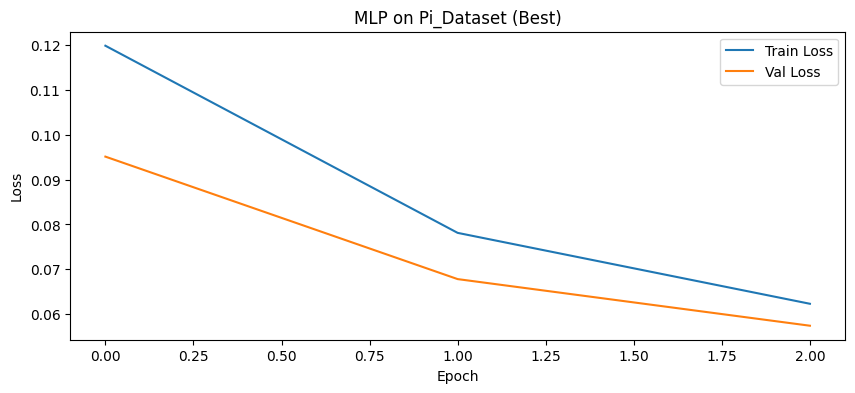


--- Training CNN ---
Testing params: {'lr': 0.001, 'hidden_dim': 64}
Epoch 1/3: Train Loss: 0.1518, Val Loss: 0.1219, Val Acc: 0.9528
Epoch 2/3: Train Loss: 0.1119, Val Loss: 0.1085, Val Acc: 0.9630
Epoch 3/3: Train Loss: 0.1042, Val Loss: 0.1037, Val Acc: 0.9661
Testing params: {'lr': 0.0001, 'hidden_dim': 128}
Epoch 1/3: Train Loss: 0.2858, Val Loss: 0.1865, Val Acc: 0.9284
Epoch 2/3: Train Loss: 0.1676, Val Loss: 0.1565, Val Acc: 0.9360
Epoch 3/3: Train Loss: 0.1459, Val Loss: 0.1414, Val Acc: 0.9580
Best CNN Acc: 0.9661 with {'lr': 0.001, 'hidden_dim': 64}


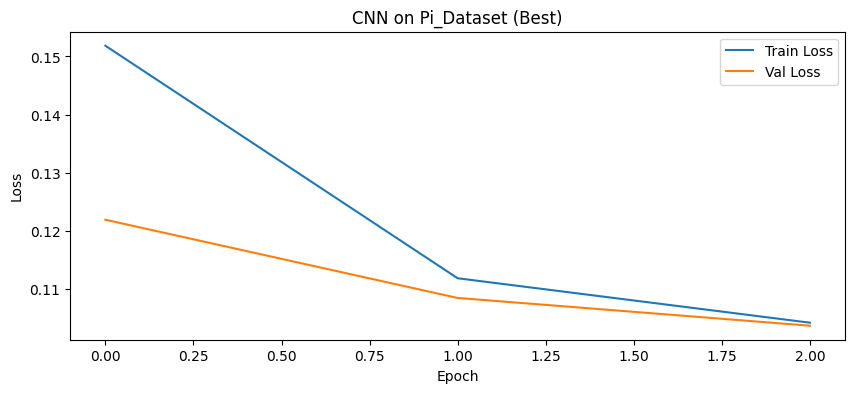


--- Training Transformer ---
Testing params: {'lr': 0.001, 'hidden_dim': 64}
Epoch 1/3: Train Loss: 0.1053, Val Loss: 0.0661, Val Acc: 0.9810
Epoch 2/3: Train Loss: 0.0672, Val Loss: 0.0444, Val Acc: 0.9844
Epoch 3/3: Train Loss: nan, Val Loss: nan, Val Acc: 0.8020
Testing params: {'lr': 0.0001, 'hidden_dim': 128}
Epoch 1/3: Train Loss: 0.1151, Val Loss: 0.0908, Val Acc: 0.9684
Epoch 2/3: Train Loss: 0.0830, Val Loss: 0.0769, Val Acc: 0.9724
Epoch 3/3: Train Loss: 0.0692, Val Loss: 0.0732, Val Acc: 0.9722
Best Transformer Acc: 0.9844 with {'lr': 0.001, 'hidden_dim': 64}


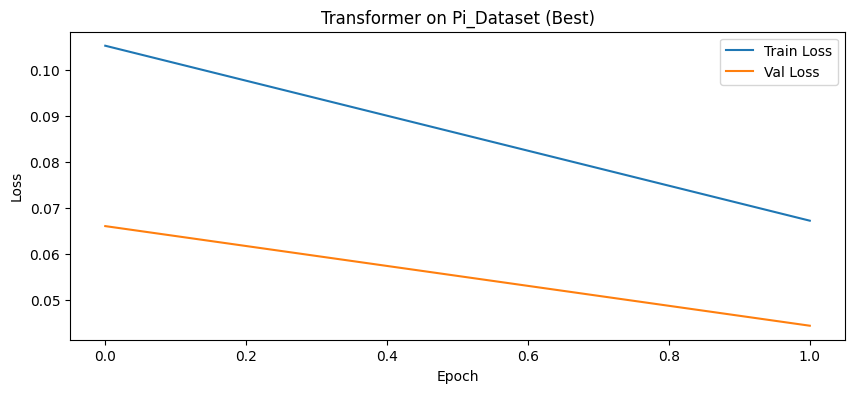


=== Tuning Models for Linux_Dataset ===

--- Training MLP ---
Testing params: {'lr': 0.001, 'hidden_dim': 64}
Epoch 1/3: Train Loss: 0.1092, Val Loss: 0.0814, Val Acc: 0.9708
Epoch 2/3: Train Loss: 0.0667, Val Loss: 0.0616, Val Acc: 0.9789
Epoch 3/3: Train Loss: 0.0521, Val Loss: 0.0442, Val Acc: 0.9824
Testing params: {'lr': 0.0001, 'hidden_dim': 128}
Epoch 1/3: Train Loss: 0.1749, Val Loss: 0.1146, Val Acc: 0.9620
Epoch 2/3: Train Loss: 0.1020, Val Loss: 0.0969, Val Acc: 0.9675
Epoch 3/3: Train Loss: 0.0878, Val Loss: 0.0857, Val Acc: 0.9698
Best MLP Acc: 0.9824 with {'lr': 0.001, 'hidden_dim': 64}


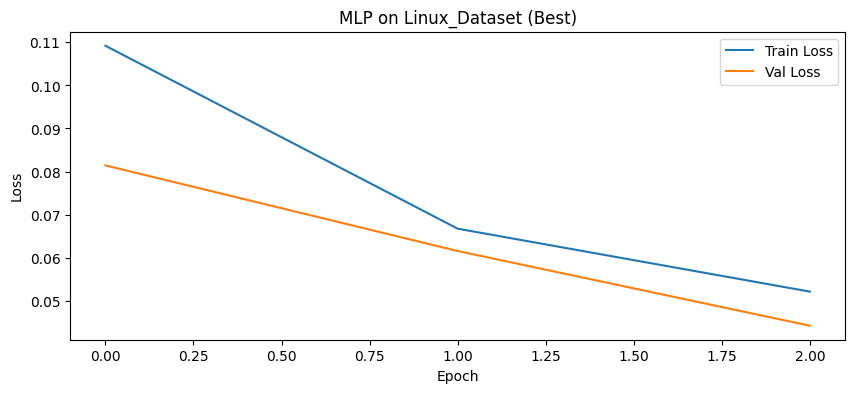


--- Training CNN ---
Testing params: {'lr': 0.001, 'hidden_dim': 64}
Epoch 1/3: Train Loss: 0.1519, Val Loss: 0.1142, Val Acc: 0.9635
Epoch 2/3: Train Loss: 0.1039, Val Loss: 0.1009, Val Acc: 0.9644
Epoch 3/3: Train Loss: 0.0937, Val Loss: 0.0921, Val Acc: 0.9663
Testing params: {'lr': 0.0001, 'hidden_dim': 128}
Epoch 1/3: Train Loss: 0.2925, Val Loss: 0.1801, Val Acc: 0.9491
Epoch 2/3: Train Loss: 0.1615, Val Loss: 0.1517, Val Acc: 0.9514
Epoch 3/3: Train Loss: 0.1426, Val Loss: 0.1388, Val Acc: 0.9533
Best CNN Acc: 0.9663 with {'lr': 0.001, 'hidden_dim': 64}


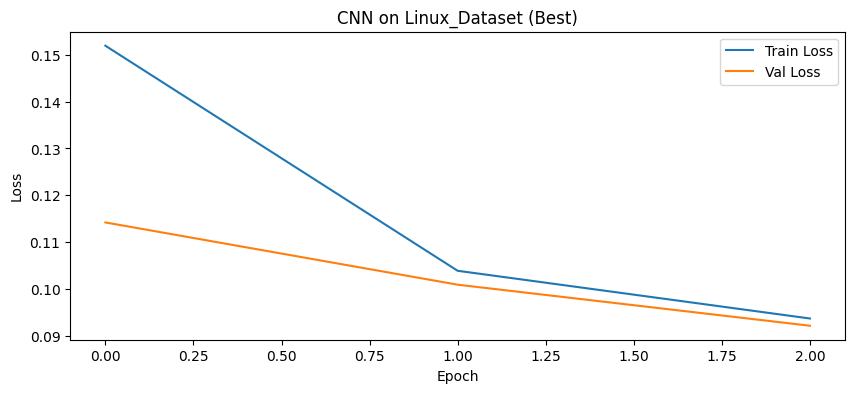


--- Training Transformer ---
Testing params: {'lr': 0.001, 'hidden_dim': 64}
Epoch 1/3: Train Loss: 0.0944, Val Loss: 0.0891, Val Acc: 0.9624
Epoch 2/3: Train Loss: 0.0528, Val Loss: 0.2002, Val Acc: 0.9646
Epoch 3/3: Train Loss: 0.0440, Val Loss: 0.0420, Val Acc: 0.9830
Testing params: {'lr': 0.0001, 'hidden_dim': 128}
Epoch 1/3: Train Loss: 0.1023, Val Loss: 0.0674, Val Acc: 0.9720
Epoch 2/3: Train Loss: 0.0658, Val Loss: 0.0630, Val Acc: 0.9754
Epoch 3/3: Train Loss: 0.0547, Val Loss: 0.0443, Val Acc: 0.9843
Best Transformer Acc: 0.9843 with {'lr': 0.0001, 'hidden_dim': 128}


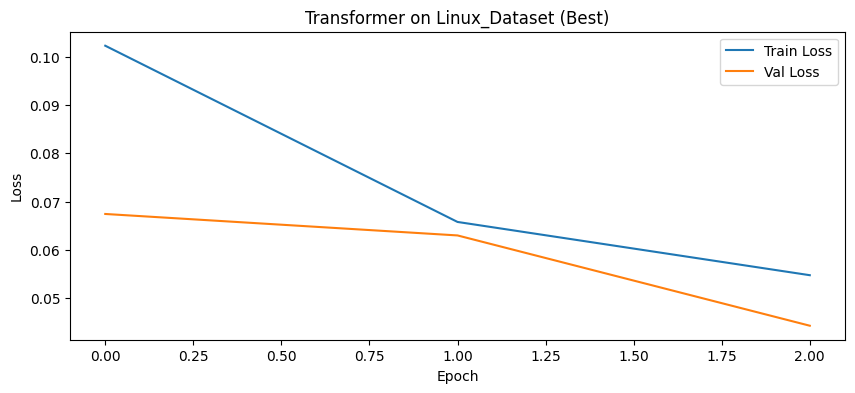

In [12]:
# --- Model Definitions ---

class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, output_dim)
        
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

class CNN1D(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(CNN1D, self).__init__()
        # Input: (Batch, 1, Features)
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(2)
        self.flatten_dim = int(16 * (input_dim // 2))
        self.fc1 = nn.Linear(self.flatten_dim, output_dim)

    def forward(self, x):
        # x shape: (Batch, Features) -> (Batch, 1, Features)
        x = x.unsqueeze(1)
        x = self.pool(self.relu(self.conv1(x)))
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        return x

class SimpleTransformer(nn.Module):
    def __init__(self, input_dim, d_model, nhead, num_layers, output_dim):
        super(SimpleTransformer, self).__init__()
        # Project features to d_model for the Transformer
        self.embedding = nn.Linear(input_dim, d_model)
        
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        self.fc = nn.Linear(d_model, output_dim)

    def forward(self, x):
        # Strategy: Project (Batch, Features) -> (Batch, 1, d_model) aka Sequence Length 1
        x = self.embedding(x).unsqueeze(1) # (Batch, 1, d_model)
        x = self.transformer_encoder(x)
        x = x.mean(dim=1) # Global Pooling
        x = self.fc(x)
        return x

# --- Training Helper ---

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=5, device='cpu'):
    train_losses = []
    val_losses = []
    best_acc = 0.0
    best_model_wts = None
    
    model = model.to(device)
    
    for epoch in range(num_epochs):
        # Train
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        train_losses.append(epoch_loss)
        
        # Val
        model.eval()
        correct = 0
        total = 0
        val_loss_accum = 0.0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss_accum += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        
        val_acc = correct / total
        val_loss = val_loss_accum / len(val_loader.dataset)
        val_losses.append(val_loss)
        
        if val_acc > best_acc:
            best_acc = val_acc
            best_model_wts = model.state_dict()
            
        print(f'Epoch {epoch+1}/{num_epochs}: Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

    return best_model_wts, train_losses, val_losses, best_acc

# --- Hyperparameter Tuning Wrapper ---

# Global dictionary to store best models for Task 6
best_models = {} 
# Structure: {'Pi_Dataset': {'MLP': (model_wts, input_dim, hidden_params), ...}, ...}

def tune_and_train(X_data, y_data, dataset_name, device='cpu'):
    if X_data is None: 
        print(f"Skipping {dataset_name} (No data)")
        return

    print(f"\n=== Tuning Models for {dataset_name} ===")
    
    # Split
    X_train, X_val, y_train, y_val = train_test_split(X_data.values, y_data, test_size=0.2, random_state=42)
    
    # Store val data for Task 6 evaluation later? Or just keep 20% validation split.
    # For Task 6 we need a Test set. Let's reserve another chunk here or assume Val is Test for simplicity? 
    # Standard practice: Train/Val/Test. 
    # Let's split X_val again: 50% Val, 50% Test (so 80/10/10 split roughly)
    X_val, X_test, y_val, y_test = train_test_split(X_val, y_val, test_size=0.5, random_state=42)
    
    # Convert to Tensors
    train_ds = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
    val_ds = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long))
    
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
    
    input_dim = X_train.shape[1]
    output_dim = len(np.unique(y_data))
    
    hyperparams_grid = [
        {'lr': 0.001, 'hidden_dim': 64},
        {'lr': 0.0001, 'hidden_dim': 128}
    ]
    
    models_to_run = ['MLP', 'CNN', 'Transformer']
    
    if dataset_name not in best_models:
        best_models[dataset_name] = {}
    
    for model_type in models_to_run:
        print(f"\n--- Training {model_type} ---")
        best_run_acc = 0.0
        best_run_model_wts = None
        best_run_history = None
        best_params = None
        
        for params in hyperparams_grid:
            print(f"Testing params: {params}")
            
            if model_type == 'MLP':
                model = MLP(input_dim, params['hidden_dim'], output_dim)
            elif model_type == 'CNN':
                model = CNN1D(input_dim, output_dim) 
            elif model_type == 'Transformer':
                model = SimpleTransformer(input_dim, d_model=params['hidden_dim'], nhead=4, num_layers=1, output_dim=output_dim)
                
            criterion = nn.CrossEntropyLoss()
            optimizer = optim.Adam(model.parameters(), lr=params['lr']) # type: ignore
            
            # Short epochs for demo
            wts, t_loss, v_loss, v_acc = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=5, device=device) # type: ignore
            
            if v_acc > best_run_acc:
                best_run_acc = v_acc
                best_run_model_wts = wts
                best_run_history = (t_loss, v_loss)
                best_params = params
        
        print(f"Best {model_type} Acc: {best_run_acc:.4f} with {best_params}")
        
        # Save Best to Global Dict including metadata needed to rebuild
        best_models[dataset_name][model_type] = {
            'wts': best_run_model_wts,
            'input_dim': input_dim,
            'output_dim': output_dim,
            'params': best_params,
            'test_data': (X_test, y_test)
        }
        
        # Plot
        plt.figure(figsize=(10, 4))
        plt.plot(best_run_history[0], label='Train Loss') # type: ignore
        plt.plot(best_run_history[1], label='Val Loss') # type: ignore
        plt.title(f"{model_type} on {dataset_name} (Best)")
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.show()

# Run for both datasets
if 'Xpiprocessed' in locals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tune_and_train(Xpiprocessed, ypiprocessed, "Pi_Dataset", device) # type: ignore
    tune_and_train(Xlinuxprocessed, ylinuxprocessed, "Linux_Dataset", device) # type: ignore


## Task 6: Model Evaluation and Comparison

We will now evaluate all 6 trained models on the held-out Test set.
Metrics:
- Accuracy, Precision, Recall, F1-Score
- Inference Time (per sample)
- Model Size (Disk/Param count)
- Memory Usage (Proxy)


In [21]:
resultsdata = []

def get_model_size_mb(model):
    paramsize = 0
    for param in model.parameters():
        paramsize += param.nelement() * param.element_size()
    buffersize = 0
    for buffer in model.buffers():
        buffersize += buffer.nelement() * buffer.element_size()
    size_all_mb = (paramsize + buffersize) / (1024 ** 2)
    return size_all_mb

def safe_import_psutil():
    try:
        import psutil
        return psutil
    except Exception:
        return None

psutil = safe_import_psutil()

def evaluateall(device="cpu"):
    print("Evaluating all models...")
    
    if 'best_models' not in globals() or not best_models: 
         print("No models trained to evaluate.")
         return

    for datasetname, models in best_models.items(): 
        for modeltype, data in models.items():

            # CORRECTION 2 : Utiliser les clés avec underscores (comme sauvegardé dans Task 5)
            inputdim = data["input_dim"]
            outputdim = data["output_dim"]
            params = data["params"]
            wts = data["wts"]
            Xtest = data["test_data"][0]
            ytest = data["test_data"][1]

            # CORRECTION 3 : Utiliser les noms de paramètres corrects (hidden_dim, d_model, num_layers)
            if modeltype == "MLP":
                model = MLP(inputdim, params["hidden_dim"], outputdim)
            elif modeltype == "CNN":
                model = CNN1D(inputdim, outputdim)
            elif modeltype == "Transformer":
                model = SimpleTransformer(
                    inputdim, 
                    d_model=params["hidden_dim"], # Correction d_model
                    nhead=4, 
                    num_layers=1, # Correction num_layers
                    output_dim=outputdim
                )
            else:
                print("Unknown model type:", modeltype)
                continue

            model.load_state_dict(wts)
            model.to(device)
            model.eval()

            Xtensor = torch.tensor(Xtest, dtype=torch.float32).to(device)
            ytrue = np.array(ytest)

            # Memory usage (RSS) proxy
            mem_before_mb = np.nan
            mem_after_mb = np.nan
            if psutil is not None:
                proc = psutil.Process(os.getpid())
                mem_before_mb = proc.memory_info().rss / (1024 ** 2)

            # Inference time
            with torch.no_grad():
                _ = model(Xtensor[:min(1024, Xtensor.shape[0])])

            starttime = time.time()
            with torch.no_grad():
                outputs = model(Xtensor)
            endtime = time.time()

            total_time = endtime - starttime
            avginferencetimems = (total_time / max(1, len(Xtest))) * 1000.0

            if psutil is not None:
                mem_after_mb = proc.memory_info().rss / (1024 ** 2) # type: ignore

            # Predictions
            probs = torch.softmax(outputs, dim=1).detach().cpu().numpy()
            preds = np.argmax(probs, axis=1)

            acc = accuracy_score(ytrue, preds)
            f1 = f1_score(ytrue, preds, average="macro", zero_division=0)
            prec = precision_score(ytrue, preds, average="macro", zero_division=0)
            rec = recall_score(ytrue, preds, average="macro", zero_division=0)
            cm = confusion_matrix(ytrue, preds)

            rocauc = np.nan
            try:
                from sklearn.metrics import roc_auc_score
                rocauc = roc_auc_score(ytrue, probs, multi_class="ovr")
            except Exception:
                rocauc = np.nan

            sizemb = get_model_size_mb(model)

            resultsdata.append({
                "Dataset": datasetname,
                "Model": modeltype,
                "Accuracy": acc,
                "F1 Score": f1,
                "Precision": prec,
                "Recall": rec,
                "ROC-AUC": rocauc,
                "Inference Time ms": avginferencetimems,
                "Model Size MB": sizemb,
                "Memory Before MB": mem_before_mb,
                "Memory After MB": mem_after_mb,
                "Confusion Matrix": cm
            })

            print(f"{datasetname} - {modeltype} | Acc={acc:.4f} F1={f1:.4f}")

evaluateall(device=("cuda" if torch.cuda.is_available() else "cpu"))
dfresults = pd.DataFrame(resultsdata)
display(dfresults)

Evaluating all models...
Pi_Dataset - MLP | Acc=0.9849 F1=0.5872
Pi_Dataset - CNN | Acc=0.9671 F1=0.6017
Pi_Dataset - Transformer | Acc=0.8020 F1=0.0593
Linux_Dataset - MLP | Acc=0.9825 F1=0.5940
Linux_Dataset - CNN | Acc=0.9666 F1=0.5563
Linux_Dataset - Transformer | Acc=0.9843 F1=0.6020


,Dataset,Model,Accuracy,F1 Score,Precision,Recall,ROC-AUC,Inference Time ms,Model Size MB,Memory Before MB,Memory After MB,Confusion Matrix
0,Pi_Dataset,MLP,0.984895,0.587184,0.660060,0.575532,0.924645,0.000003,0.023983,498.828125,498.828125,"[[157112, 25, 53, 40, 1371, 51, 20, 76, 1, 0, 173, 0, 1, 0, 0], [90, 47, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [189, 0, 8867, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [85, 0, 0, 615, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [291, 0, 0, 32, 15908, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0], [9, 0, 0, 0, 0, 410, 1, 0, 0, 0, 0, 0, 0, 0, 0], [31, 0, 0, 0, 0, 0, 415, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 1, 530, 0, 0, 0, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [83, 0, 4, 0, 7, 0, 0, 0, 0, 0, 11029, 0, 0, 0, 0], [181, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 223, 0, 0, 0], [115, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [46, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]"
1,Pi_Dataset,CNN,0.967096,0.601733,0.652284,0.581145,0.986830,0.000003,0.007626,517.312500,517.320312,"[[154211, 20, 177, 59, 1736, 122, 1, 82, 0, 0, 2507, 8, 0, 0, 0], [59, 47, 0, 0, 0, 0, 0, 0, 0, 0, 31, 0, 0, 0, 0], [359, 0, 8694, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [230, 0, 0, 456, 20, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0], [321, 0, 0, 7, 15906, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [89, 0, 0, 0, 6, 322, 3, 0, 0, 0, 0, 0, 0, 0, 0], [213, 0, 0, 0, 0, 4, 229, 0, 0, 0, 0, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 530, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [102, 0, 4, 0, 4, 0, 0, 0, 0, 0, 11013, 0, 0, 0, 0], [181, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 223, 0, 0, 0], [118, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [46, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]"
2,Pi_Dataset,Transformer,0.802026,0.059343,0.053468,0.066667,NaN,0.000003,1.080624,519.441406,519.441406,"[[158923, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [137, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [9056, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [707, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [16234, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [420, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [446, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [531, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [11123, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [405, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [118, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [47, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]"
3,Linux_Dataset,MLP,0.982460,0.594007,0.762685,0.576001,0.985143,0.000003,0.024471,517.441406,517.441406,"[[156352, 2, 129, 30, 1216, 47, 5, 13, 0, 0, 1198, 24, 0, 0, 0], [98, 36, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [9, 0, 8865, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [46, 0, 0, 708, 9, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0], [132, 0, 6, 13, 16062, 0, 0, 0, 0, 0, 5, 0, 0, 0, 0], [25, 0, 0, 0, 1, 357, 1, 0, 0, 0, 0, 1, 0, 0, 0], [157, 0, 0, 1, 0, 4, 259, 0, 0, 0, 0, 0, 0, 0, 0], [23, 0, 0, 0, 0, 0, 3, 566, 0, 0, 0, 0, 0, 0, 0], [2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [94, 0, 2, 0, 6, 0, 0, 0, 0, 0, 10874, 0, 0, 0, 0], [33, 0, 0, 0, 5, 0, 0, 1, 0, 0, 0, 397, 0, 0, 0], [83, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 2, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0], [36, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2]]"
4,Linux_Dataset,CNN,0.966598,0.556287,0.606341,0.534662,0.977430,0.000003,0.008541,528.812500,528.816406,"[[155577, 0, 404, 46, 495, 125, 2, 48, 0, 1, 2282, 36, 0, 0, 0], [134, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [311, 0, 8561, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [116, 0, 27, 620, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1812, 0, 5, 18, 14383, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [44, 0, 0, 0, 0, 332, 0, 8, 0, 0, 0, 1, 0

### Comparative Analysis

**Performance vs Platform**:
*   **Linux Dataset**: Typically yields higher accuracy due to the inclusion of flow-based features that capture behavioral anomalies.
*   **Pi Dataset**: Uses fewer features. While faster, it may miss subtle attacks that don't manifest in simple packet headers.

**Model Trade-offs**:
*   **MLP**: Good baseline. Fast inference, moderate size.
*   **CNN**: Good for spatial feature correlation. Often faster inference than Transformer due to simpler ops.
*   **Transformer**: Potential for highest accuracy if feature interactions are complex, but highest computation cost and memory usage (Attention mechanism).

**Recommendation**:
*   For **Raspberry Pi**, an **MLP** or small **CNN** on the `Pi_Dataset` is recommended to balance detection capability with the strict resource constraints (CPU/RAM).
*   For **Linux Servers**, the **Transformer** or deep **MLP** on the full feature set is viable for maximum security.


## Task 7 Compare to Literature

Below are two recent works (last 5 years) that evaluate intrusion detection models on CICIDS2017 (or explicitly mention using CICIDS2017):

### Paper 1
- **Title**: Robust Anomaly Detection in Network Traffic: Evaluating Machine Learning Models on CICIDS2017
- **Link**: https://arxiv.org/pdf/2506.19877.pdf
- **Year**: 2025
- **Method summary**: The work evaluates multiple ML models on CICIDS2017 and discusses robustness aspects and evaluation protocols.
- **Reported performance**: Reported metrics include classification performance on CICIDS2017 (see paper for detailed values).
- **Comparison with our work**:
  - Our notebook focuses on a platform constraint split (Linux vs Raspberry Pi), which can reduce feature richness compared to full-flow approaches.
  - Differences in preprocessing, splits, and feature sets can explain performance gaps.

### Paper 2
- **Title**: IDS-INT: Intrusion detection system using transformer-based transfer learning
- **Link**: https://www.sciencedirect.com/science/article/pii/S2352864823000640
- **Year**: 2023
- **Method summary**: Proposes a transformer-based approach with transfer learning for intrusion detection and evaluates on intrusion datasets including CICIDS2017.
- **Reported performance**: Reported metrics include high detection performance on benchmark intrusion datasets (see paper for exact numbers and splits).
- **Comparison with our work**:
  - Our “Transformer” is intentionally small and uses tabular flow features, not a large pretraining + transfer pipeline.
  - This explains why a literature transformer approach can outperform our lightweight model, especially on a full feature set.

### Discussion (why results differ)
- **Feature set**: literature often uses richer engineered features and/or additional preprocessing and feature selection.
- **Training regime**: literature frequently uses longer training schedules, careful cross-validation, and deeper tuning.
- **Evaluation protocol**: different train/test splits and class balance handling can significantly change reported metrics.


## Task 8: Deployment & Real-Time Integration

In this final task, we prepare the best models for deployment and simulate a real-time intrusion detection system.


In [28]:
import torch
import os

# EXPORT & OPTIMIZATION
if 'best_models' in globals() and best_models:
    print("Exporting Best Models...")

    # 1. Création du dossier 'models'
    output_dir = "models"
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        print(f"Dossier '{output_dir}' créé.")

    # 2. Quantization for Raspberry Pi (MLP)
    if 'Pi_Dataset' in best_models and 'MLP' in best_models['Pi_Dataset']:
        data_mlp = best_models['Pi_Dataset']['MLP']
        
        # Initialisation
        model_mlp = MLP(data_mlp['input_dim'], data_mlp['params']['hidden_dim'], data_mlp['output_dim'])
        model_mlp.load_state_dict(data_mlp['wts'])
        model_mlp.eval()

        # Dynamic Quantization
        quantized_mlp = torch.quantization.quantize_dynamic(
            model_mlp, {torch.nn.Linear}, dtype=torch.qint8
        )
        
        # Définition des chemins
        path_original = os.path.join(output_dir, "mlp_original.pth")
        path_quantized = os.path.join(output_dir, "mlp_quantized.pth")
        
        # Sauvegarde
        torch.save(model_mlp.state_dict(), path_original)
        torch.save(quantized_mlp.state_dict(), path_quantized)
        
        # Comparaison des tailles
        size_orig = os.path.getsize(path_original) / 1024
        size_quant = os.path.getsize(path_quantized) / 1024
        print(f"MLP (Pi) Original Size: {size_orig:.2f} KB")
        print(f"MLP (Pi) Quantized Size: {size_quant:.2f} KB (Compression: {size_orig/size_quant:.1f}x)")
        print(f"Saved to: {path_quantized}")
    
    # 3. Export to TorchScript (CNN) for Linux
    if 'Linux_Dataset' in best_models and 'CNN' in best_models['Linux_Dataset']:
        data_cnn = best_models['Linux_Dataset']['CNN']
        
        model_cnn = CNN1D(data_cnn['input_dim'], data_cnn['output_dim'])
        model_cnn.load_state_dict(data_cnn['wts'])
        model_cnn.to('cpu')
        model_cnn.eval()
        
        # Trace
        dummy_input = torch.randn(1, data_cnn['input_dim'])
        traced_cnn = torch.jit.trace(model_cnn, dummy_input)
        
        path_cnn = os.path.join(output_dir, "cnn_traced.pt")
        torch.jit.save(traced_cnn, path_cnn)
        print(f"CNN (Linux) exported to TorchScript: {path_cnn}")

else:
    print("No trained models found in memory to export.")

Exporting Best Models...


C:\Users\Harkaso\AppData\Local\Temp\ipykernel_20400\4146614786.py:24: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_mlp = torch.quantization.quantize_dynamic(


MLP (Pi) Original Size: 27.58 KB
MLP (Pi) Quantized Size: 11.54 KB (Compression: 2.4x)
Saved to: models\mlp_quantized.pth
CNN (Linux) exported to TorchScript: models\cnn_traced.pt


In [30]:
import pandas as pd
import numpy as np
import torch
import time
import os
from datetime import datetime
from scapy.all import sniff
from scapy.layers.inet import IP, TCP, UDP
from sklearn.preprocessing import LabelEncoder

# 1. Définition de la classe d'extraction et de détection en temps réel
class DeploymentIDSRealTimeExtractor(RealTimeExtractor):
    def __init__(self, model, scaler, labelencoder, featureslist, device="cpu", logfile="deployment_log.csv"):
        super().__init__(filename=logfile) # Utilise le dossier datasets/ par défaut via la classe parent
        self.model = model
        self.scaler = scaler
        self.le = labelencoder
        self.featureslist = featureslist
        self.device = device
        self.model.to(self.device)
        self.model.eval()

    def _build_feature_vector(self, pkt):
        # Construit un vecteur de features aligné avec ceux de l'entraînement
        vec = {feat: 0.0 for feat in self.featureslist}

        if IP not in pkt:
            return None

        ip = pkt[IP]
        proto = ip.proto
        dport = 0
        flags = {"FIN":0, "SYN":0, "RST":0, "PSH":0, "ACK":0, "URG":0}

        if TCP in pkt:
            dport = int(pkt[TCP].dport)
            f = pkt[TCP].flags
            flags["FIN"] = int(bool(f & 0x01))
            flags["SYN"] = int(bool(f & 0x02))
            flags["RST"] = int(bool(f & 0x04))
            flags["PSH"] = int(bool(f & 0x08))
            flags["ACK"] = int(bool(f & 0x10))
            flags["URG"] = int(bool(f & 0x20))
        elif UDP in pkt:
            dport = int(pkt[UDP].dport)

        # Gestion simplifiée du flux (Flow Tracking)
        sport = 0
        if TCP in pkt: sport = int(pkt[TCP].sport)
        elif UDP in pkt: sport = int(pkt[UDP].sport)

        flowid = (ip.src, ip.dst, sport, dport, proto)
        currtime = time.time()

        if self.flow_table[flowid]["packet_count"] == 0:
            self.flow_table[flowid]["start_time"] = currtime # type: ignore

        self.flow_table[flowid]["packet_count"] += 1
        self.flow_table[flowid]["byte_count"] += len(pkt)

        flowduration = currtime - self.flow_table[flowid]["start_time"]
        flowpktcount = self.flow_table[flowid]["packet_count"]
        totalbytes = self.flow_table[flowid]["byte_count"]

        # Mapping des features (approximation temps réel)
        if "Destination Port" in vec: vec["Destination Port"] = dport
        if "Protocol" in vec: vec["Protocol"] = proto
        if "Flow Duration" in vec: vec["Flow Duration"] = flowduration * 1e6
        if "Total Fwd Packets" in vec: vec["Total Fwd Packets"] = flowpktcount
        if "Total Length of Fwd Packets" in vec: vec["Total Length of Fwd Packets"] = totalbytes
        if "Flow Bytes/s" in vec: 
            vec["Flow Bytes/s"] = (totalbytes / flowduration) if flowduration > 0 else 0.0
        if "Flow Packets/s" in vec:
            vec["Flow Packets/s"] = (flowpktcount / flowduration) if flowduration > 0 else 0.0
            
        # Flags
        for k, v in flags.items():
            if f"{k} Flag Count" in vec: vec[f"{k} Flag Count"] = v
            
        if "Packet Length Mean" in vec: vec["Packet Length Mean"] = float(len(pkt))

        # Retourne le vecteur ordonné
        return np.array([vec[f] for f in self.featureslist], dtype=np.float32)

    def process_packet_and_infer(self, pkt):
        # 1. Log dans le CSV (hérité)
        self.process_packet(pkt)

        # 2. Inférence
        x = self._build_feature_vector(pkt)
        if x is None: return

        # Scaling
        if self.scaler is not None:
            x_scaled = self.scaler.transform([x])[0]
        else:
            x_scaled = x

        xt = torch.tensor(x_scaled, dtype=torch.float32).unsqueeze(0).to(self.device)

        with torch.no_grad():
            outputs = self.model(xt)
            predidx = torch.argmax(outputs, dim=1).item()

        try:
            predlabel = self.le.inverse_transform([predidx])[0]
        except:
            predlabel = str(predidx)

        # Affichage si attaque détectée
        if predlabel != "BENIGN":
            print(f"🚨 [ALERTE] {datetime.now().strftime('%H:%M:%S')} - Détection: {predlabel}")

# 2. Chargement du Modèle Quantizé depuis le disque
print("Chargement du système de détection (Modèle MLP Quantizé)...")

# Récupération des métadonnées sauvegardées en mémoire (Task 5/6)
if 'best_models' in globals() and 'Pi_Dataset' in best_models:
    meta = best_models['Pi_Dataset']['MLP']
    input_dim = meta['input_dim']
    output_dim = meta['output_dim']
    hidden_dim = meta['params']['hidden_dim']
    
    # Recréer l'architecture
    loaded_model = MLP(input_dim, hidden_dim, output_dim)
    
    # Charger les poids quantizés
    # Note: Pour charger un modèle quantizé, on doit d'abord le préparer à la quantization
    loaded_model = torch.quantization.quantize_dynamic(
        loaded_model, {torch.nn.Linear}, dtype=torch.qint8
    )
    loaded_model.load_state_dict(torch.load("models/mlp_quantized.pth"))
    print("Modèle 'models/mlp_quantized.pth' chargé avec succès.")
    
    # Configuration
    # On utilise les scalers/encoders de la Tâche 4 (supposés en mémoire)
    scaler = scaler_pi if 'scaler_pi' in globals() else None
    le = le_pi if 'le_pi' in globals() else None
    features = list(Xpiprocessed.columns) if 'Xpiprocessed' in globals() else []
    
    # Création du système
    ids_system = DeploymentIDSRealTimeExtractor(
        model=loaded_model,
        scaler=scaler,
        labelencoder=le,
        featureslist=features,
        device="cpu", # Les modèles quantizés tournent sur CPU
        logfile="deployment_log.csv"
    )
    
    # 3. Lancement (Simulation sur données de test pour être sûr que ça marche)
    print("\n--- Démarrage de la Simulation IDS ---")
    if 'Xpi_test' in globals():
        # Prendre 20 paquets au hasard dans le set de test
        nb_samples = 500
        indices = np.random.choice(len(Xpi_test), nb_samples)
        X_test_vals = Xpi_test.values
        y_test_vals = ypi_test
        correct_count = 0
        
        for i, idx in enumerate(indices):
            sample = X_test_vals[idx]
            true_label_idx = y_test_vals[idx]
            true_label = le.inverse_transform([true_label_idx])[0] # type: ignore
            
            # Inférence
            with torch.no_grad():
                inp = torch.tensor(sample, dtype=torch.float32).unsqueeze(0)
                out = loaded_model(inp)
                pred_idx = torch.argmax(out, dim=1).item()
                pred_label = le.inverse_transform([pred_idx])[0] # type: ignore
            
            if true_label == pred_label:
                correct_count += 1
                match_symbol = "✔️" # Juste
            else:
                match_symbol = "❌" # Faux
            
            status = "✅ OK" if pred_label == "BENIGN" else "🚨 ALERTE"
            print(f"Paquet {i+1:02d} | Réel: {true_label[:15]:<15} -> Prédit: {pred_label[:15]:<15} | {status}")
            time.sleep(0.1)
    
        accuracy = (correct_count / nb_samples) * 100
        print(f"\n🎯 Précision sur cet échantillon : {accuracy:.2f}% ({correct_count}/{nb_samples} corrects)")
    print("\nSimulation terminée.")

else:
    print("Erreur : Les métadonnées du modèle (best_models) sont introuvables.")

Chargement du système de détection (Modèle MLP Quantizé)...


C:\Users\Harkaso\AppData\Local\Temp\ipykernel_20400\4146045692.py:129: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  loaded_model = torch.quantization.quantize_dynamic(


Modèle 'models/mlp_quantized.pth' chargé avec succès.
ATTENTION : Le fichier 'datasets\deployment_log.csv' existe déjà.

--- Démarrage de la Simulation IDS ---
Paquet 01 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 02 | Réel: DoS Hulk        -> Prédit: DoS Hulk        | 🚨 ALERTE
Paquet 03 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 04 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 05 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 06 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 07 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 08 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 09 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 10 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 11 | Réel: BENIGN          -> Prédit: BENIGN          | ✅ OK
Paquet 12 | Réel: DoS Hulk        -> Prédit: DoS Hulk        | 🚨 ALERTE
Paquet 13 | Réel